In [20]:

import numpy as np
import pandas as pd

data_path = "/content/diabetes.csv"

df = pd.read_csv(data_path)

df.head()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72.0,35,169.5,33.6,0.627,50,1
1,85,66.0,29,102.5,26.6,0.351,31,0
2,183,64.0,32,169.5,23.3,0.672,32,1
3,89,66.0,23,94.0,28.1,0.167,21,0
4,137,40.0,35,168.0,43.1,2.288,33,1


In [21]:
from sklearn.model_selection import train_test_split
# Prepare features and target variable
X = df[['Age', 'BMI', 'BloodPressure', 'Insulin', 'Glucose', 'DiabetesPedigreeFunction']]
y = df['Outcome']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LogisticRegression

# Initialize and train the logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)



LogisticRegression(max_iter=1000)

In [ ]:
X_test

,Age,BMI,BloodPressure,Insulin,Glucose,DiabetesPedigreeFunction
668,43,34.0,58.0,190.0,98,0.430
324,21,35.7,75.0,102.5,112,0.148
624,21,30.8,64.0,102.5,108,0.158
690,34,24.6,80.0,102.5,107,0.856
473,50,29.9,90.0,102.5,136,0.210
...,...,...,...,...,...,...
355,49,30.4,88.0,169.5,165,0.302
534,24,33.3,56.0,56.0,77,1.251
344,57,36.8,72.0,102.5,95,0.485
296,29,28.0,70.0,360.0,146,0.337


In [22]:
# Weights
print(model.coef_)

# Constant / intercept
print(model.intercept_)

[[ 0.04559683  0.09394991 -0.00964773  0.00442035  0.03010364  0.48521205]]
[-9.2358725]


In [23]:
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc
# Predict on the test set
y_pred = model.predict(X_test)

# Calculate the accuracy score
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy Score: {accuracy:.4f}')

Accuracy Score: 0.7597


In [24]:
y_pred

array([0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0])

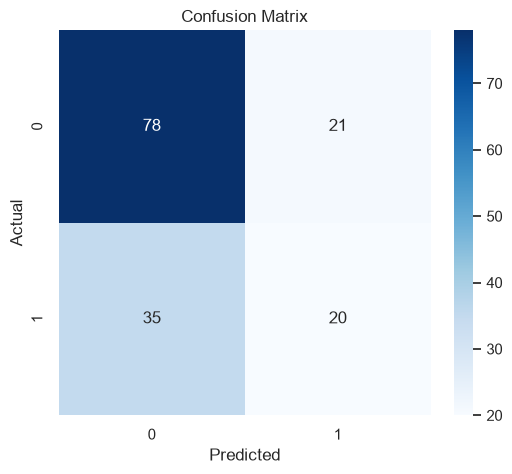

In [ ]:
# Generate the confusion matrix and visualize using heatmap
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

import matplotlib
matplotlib.use('Agg')  # Use Agg backend for headless environments
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns





In [6]:
21,35.7,75.0,102.5,112,0.148

(21, 35.7, 75.0, 102.5, 112, 0.148)

In [7]:
df.shape


(768, 8)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    float64
 2   SkinThickness             768 non-null    int64  
 3   Insulin                   768 non-null    float64
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(4)
memory usage: 48.1 KB


In [9]:
df.describe()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,121.677083,72.389323,29.089844,141.753906,32.434635,0.471876,33.240885,0.348958
std,30.464161,12.106039,8.890820,89.100847,6.880498,0.331329,11.760232,0.476951
min,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,99.750000,64.000000,25.000000,102.500000,27.500000,0.243750,24.000000,0.000000
50%,117.000000,72.000000,28.000000,102.500000,32.050000,0.372500,29.000000,0.000000
75%,140.250000,80.000000,32.000000,169.500000,36.600000,0.626250,41.000000,1.000000
max,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [10]:
df.isnull().sum()

,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [11]:
df["Outcome"].value_counts()

,count
Outcome,
0,500
1,268


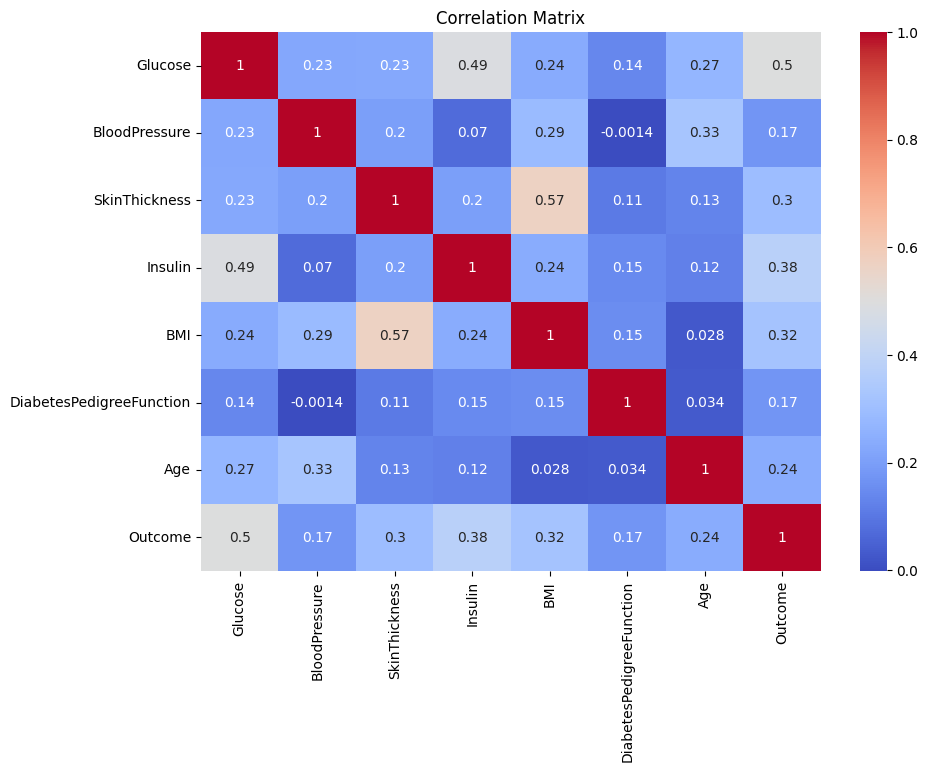

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [13]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 7)
Target shape: (768,)


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 7)
Testing data: (154, 7)


In [15]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [16]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[0 0 0 0 0 1 0 0 1 1]


In [17]:
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [[ 0.03085378 -0.00935021  0.04547116  0.00450926  0.06355115  0.46262427
   0.04303078]]
Intercept: [-9.61895872]


In [18]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

print("Predictions:", y_pred)
print("Accuracy:", accuracy_score(y_test, y_pred))

Predictions: [0 0 0 0 0 1 0 0 1 1 0 1 1 0 0 1 0 0 1 0 0 0 1 0 0 1 0 0 0 0 1 1 1 1 1 1 1
 0 0 0 0 1 0 0 0 1 1 0 0 1 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0 1 0 1 0 1 1 0 0 0
 0 1 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 1 1 1 0 0 1 0 0 0
 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 1 0 0 0 0
 0 1 0 0 1 0]
Accuracy: 0.7532467532467533


In [19]:
# Coefficients
coefficients = model.coef_[0]

# Intercept
intercept = model.intercept_[0]

# Har feature × uska coefficient
multiplication = X_test.iloc[0] * coefficients

print("Feature × Coefficient:")
print(multiplication)

# Sab values ko add karke intercept bhi add karo
result = multiplication.sum() + intercept

print("\nFinal result:", result)

Feature × Coefficient:
Glucose                     3.023670
BloodPressure              -0.542312
SkinThickness               1.500548
Insulin                     0.856760
BMI                         2.160739
DiabetesPedigreeFunction    0.198928
Age                         1.850324
Name: 668, dtype: float64

Final result: -0.5703013470139933


In [25]:
for feature, value, weight in zip(X_test.columns, row, weights):
    print(f"{feature}: {value} × {weight} = {value * weight}")

print("\nIntercept =", intercept)
print("Final =", multiplication.sum() + intercept)

NameError: name 'row' is not defined

In [26]:
weights = model.coef_[0]
intercept = model.intercept_[0]

# First test row
row = X_test.iloc[0]

# Weight × value
multiplication = row * weights

print("Values:")
print(row)

print("\nWeight × Value:")
print(multiplication)

print("\nSum:")
print(multiplication.sum())

print("\nFinal Result:")
print(multiplication.sum() + intercept)


Values:
Age                          43.00
BMI                          34.00
BloodPressure                58.00
Insulin                     190.00
Glucose                      98.00
DiabetesPedigreeFunction      0.43
Name: 668, dtype: float64

Weight × Value:
Age                         1.960664
BMI                         3.194297
BloodPressure              -0.559568
Insulin                     0.839866
Glucose                     2.950157
DiabetesPedigreeFunction    0.208641
Name: 668, dtype: float64

Sum:
8.594055978672483

Final Result:
-0.6418165242141249


In [27]:
import numpy as np

z = multiplication.sum() + intercept

sigmoid = 1 / (1 + np.exp(-z))

print("z =", z)
print("Sigmoid =", sigmoid)

z = -0.6418165242141249
Sigmoid = 0.34483602712630934


In [28]:
import numpy as np

z = multiplication.sum() + intercept

probability = 1 / (1 + np.exp(-z))

threshold = 0.5

if probability >= threshold:
    prediction = 1
else:
    prediction = 0

print("Z value:", z)
print("Sigmoid probability:", probability)
print("Threshold:", threshold)
print("Final prediction:", prediction)

Z value: -0.6418165242141249
Sigmoid probability: 0.34483602712630934
Threshold: 0.5
Final prediction: 0


In [29]:
LogisticRegression()

LogisticRegression()

In [30]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))

Decision Tree Accuracy: 0.8051948051948052


In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.8636363636363636


In [32]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, knn_pred))

KNN Accuracy: 0.8376623376623377


In [33]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svm_model = SVC()

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))

SVM Accuracy: 0.8311688311688312


In [34]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))

Naive Bayes Accuracy: 0.7792207792207793


In [35]:
results = {
    "Logistic Regression": accuracy_score(y_test, y_pred),
    "Decision Tree": accuracy_score(y_test, dt_pred),
    "Random Forest": accuracy_score(y_test, rf_pred),
    "KNN": accuracy_score(y_test, knn_pred),
    "SVM": accuracy_score(y_test, svm_pred),
    "Naive Bayes": accuracy_score(y_test, nb_pred)
}

for model, accuracy in results.items():
    print(f"{model}: {accuracy:.4f}")

Logistic Regression: 0.7597
Decision Tree: 0.8052
Random Forest: 0.8636
KNN: 0.8377
SVM: 0.8312
Naive Bayes: 0.7792


In [36]:
import pandas as pd

comparison = pd.DataFrame({
    "Algorithm": list(results.keys()),
    "Accuracy": list(results.values())
})

comparison["Accuracy (%)"] = comparison["Accuracy"] * 100

comparison

,Algorithm,Accuracy,Accuracy (%)
0,Logistic Regression,0.759740,75.974026
1,Decision Tree,0.805195,80.519481
2,Random Forest,0.863636,86.363636
3,KNN,0.837662,83.766234
4,SVM,0.831169,83.116883
5,Naive Bayes,0.779221,77.922078
